<div style="border-left: 5px solid #48C7E8; padding: 8px 0 8px 18px; margin: 0 0 12px;">
<div style="font-family: sans-serif; font-size: 12px; letter-spacing: .15em; color: #1498BC; font-weight: 700;">DEEPDIVE · AI BOOTCAMP / 01</div>
<h1 style="margin: 6px 0 2px; font-size: 30px;">Od surowych danych do pierwszej analizy</h1>
<div style="color: #6b7280;">Python · pandas · preprocessing · EDA</div>
</div>

**Cel:** przygotować zbiór danych do analizy i sprawdzić, co się w nim znajduje.

**Dane:** `penguins.csv` — syntetyczny zbiór o pingwinach, celowo zawierający błędy. Nie są to pomiary z rzeczywistego badania.

**Zasady:** uruchamiaj komórki od góry (`Shift + Enter`). Uzupełniaj wyłącznie miejsca oznaczone `# TODO`. Plik `penguins.csv` musi leżeć obok notebooka.

**Czas:** ~30–40 min · **Biblioteki:** `pandas`, `matplotlib`

### 01 / Wczytanie danych

Wczytaj `penguins.csv` do zmiennej `df` i wyświetl pierwsze pięć wierszy.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# TODO: wczytaj plik CSV
df = pd.read_csv("penguins.csv")

# TODO: wyświetl pierwsze 5 wierszy
df.head()


,penguin_id,species,island,bill_length_mm,flipper_length_mm,body_mass_g,sex
0,P001,Adelie,Torgersen,40.9,178,2950.0,female
1,P002,Chinstrap,Dream,44.8,197,4600.0,male
2,P003,Chinstrap,Dream,47.7,198,3300.0,female
3,P004,Adelie,Dream,35.5,178,3700.0,female
4,P005,Adelie,Biscoe,37.8,198,NaN,female


### 02 / Pierwszy przegląd

Sprawdź **liczbę wierszy i kolumn**, nazwy i typy kolumn oraz podstawowe statystyki dla kolumn liczbowych.

In [3]:
# TODO: rozmiar tabeli
print("Rozmiar tabeli:", df.shape)

# TODO: typy danych i braki
df.info()

# TODO: statystyki opisowe
df.describe()

Rozmiar tabeli: (98, 7)
<class 'pandas.DataFrame'>
RangeIndex: 98 entries, 0 to 97
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   penguin_id         98 non-null     str    
 1   species            98 non-null     str    
 2   island             98 non-null     str    
 3   bill_length_mm     95 non-null     float64
 4   flipper_length_mm  98 non-null     int64  
 5   body_mass_g        94 non-null     float64
 6   sex                94 non-null     str    
dtypes: float64(2), int64(1), str(4)
memory usage: 5.5 KB


,bill_length_mm,flipper_length_mm,body_mass_g
count,95.000000,98.000000,94.000000
mean,45.166316,199.714286,4314.893617
std,5.534642,12.326319,2681.225344
min,29.400000,178.000000,2150.000000
25%,41.000000,190.000000,3512.500000
50%,45.000000,198.000000,3950.000000
75%,49.350000,209.750000,4600.000000
max,56.800000,224.000000,29000.000000


### 03 / Brakujące wartości

Policz brakujące wartości w każdej kolumnie. Które kolumny wymagają uwagi?

In [4]:
# TODO: liczba braków w każdej kolumnie
df.isna().sum()

penguin_id           0
species              0
island               0
bill_length_mm       3
flipper_length_mm    0
body_mass_g          4
sex                  4
dtype: int64

### 04 / Duplikaty

Sprawdź, ile wierszy jest identycznych, a następnie usuń duplikaty.

In [5]:
# TODO: policz duplikaty
print("duplikaty:", df.duplicated().sum())

# TODO: usuń powtarzające się wiersze
df = df.drop_duplicates()

# TODO: sprawdź rozmiar po czyszczeniu
print("rozmiar po czyszczeniu:", df.shape)

duplikaty: 2
rozmiar po czyszczeniu: (96, 7)


### 05 / Niespójne kategorie

Wyświetl wartości w kolumnie `sex`. Ujednolić zapis tak, aby zostały tylko `female`, `male` i braki.

In [6]:
# TODO: jakie wartości występują w kolumnie sex?

# TODO: usuń spacje i zamień litery na małe

# TODO: sprawdź wynik
print("Przed:", df["sex"].value_counts(dropna=False))
df["sex"] = df["sex"].str.strip().str.lower()
print("Po:", df["sex"].value_counts(dropna=False))


Przed: sex
female      48
male        40
NaN          4
 FEMALE      2
Male         2
Name: count, dtype: int64
Po: sex
female    50
male      42
NaN        4
Name: count, dtype: int64


### 06 / Wartości odstające

Sprawdź maksymalną masę pingwina. **Na potrzeby tego ćwiczenia** uznaj masę powyżej `8000 g` za błąd i zastąp ją brakiem (`NaN`).

In [7]:
# TODO: maksimum masy
...

# TODO: ustaw NaN dla masy > 8000 g
...

# TODO: sprawdź maksimum jeszcze raz
...
print("Maksimum przed:", df["body_mass_g"].max())
df.loc[df["body_mass_g"] > 8000, "body_mass_g"] = float("nan")
print("Maksimum po:", df["body_mass_g"].max())


Maksimum przed: 29000.0
Maksimum po: 5750.0


### 07 / Uzupełnianie braków

Uzupełnij braki w `body_mass_g` i `bill_length_mm` **medianą**, a braki w `sex` etykietą `unknown`. Nie usuwaj wierszy.

In [8]:
# TODO: mediana masy
...

# TODO: mediana długości dzioba
...

# TODO: brak płci -> "unknown"
...

# TODO: kontrola pozostałych braków
...
df["body_mass_g"] = df["body_mass_g"].fillna(df["body_mass_g"].median())
df["bill_length_mm"] = df["bill_length_mm"].fillna(df["bill_length_mm"].median())
df["sex"] = df["sex"].fillna("unknown")
df.isna().sum()


penguin_id           0
species              0
island               0
bill_length_mm       0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

### 08 / Pierwsze EDA

Sprawdź liczebność gatunków i średnią masę dla każdego gatunku. Następnie narysuj histogram masy.

Liczebności:
species
Adelie       36
Chinstrap    35
Gentoo       25
Name: count, dtype: int64

Średnia masa [g]:
species
Adelie       3630.6
Chinstrap    3772.9
Gentoo       5016.0
Name: body_mass_g, dtype: float64


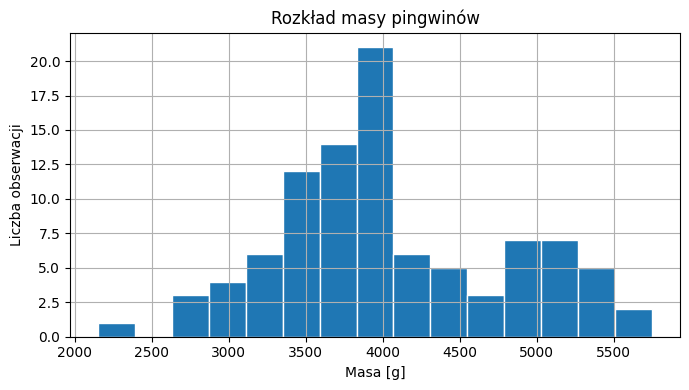

In [9]:
# TODO: liczebność gatunków
...

# TODO: średnia masa według species
...

# TODO: histogram masy (np. 15 przedziałów)
print("Liczebności:")
print(df["species"].value_counts())
print("\nŚrednia masa [g]:")
print(df.groupby("species")["body_mass_g"].mean().round(1))

ax = df["body_mass_g"].hist(bins=15, edgecolor="white", figsize=(7, 4))
ax.set(title="Rozkład masy pingwinów", xlabel="Masa [g]", ylabel="Liczba obserwacji")
plt.tight_layout()
plt.show()



### 09 / Kontrola końcowa

Potwierdź, że nie ma duplikatów ani braków. Zapisz przygotowane dane do pliku `penguins_clean.csv` (bez indeksu).

In [10]:
# TODO: liczba pozostałych braków
...

# TODO: liczba duplikatów
...

# TODO: zapisz CSV bez indeksu
...
print("Braki:", df.isna().sum().sum())
print("Duplikaty:", df.duplicated().sum())
df.to_csv("penguins_clean.csv", index=False)
print("Zapisano penguins_clean.csv")

Braki: 0
Duplikaty: 0
Zapisano penguins_clean.csv


---
### Checkpoint

Odpowiedz w 1–2 zdaniach:

1. Dlaczego **mediana** może być lepsza od średniej przy uzupełnianiu braków?
2. Dlaczego nie każdą wartość odstającą należy automatycznie usuwać?
3. Jakie informacje o gatunkach widać w `value_counts()` i `groupby()`?

**Gotowe.** Masz uporządkowany zbiór i pierwsze obserwacje z EDA.